# Bab 6 — Statistical Machine Learning

### Identitas Mahasiswa

| Detail | Identitas |
|---|---|
| Nama | Hadi Nugroho |
| NIM | 101032330235 |

**Tujuan pembelajaran.** memahami K-nearest neighbors dan pentingnya standardisasi; membangun dan membaca decision tree; memahami bagging, random forest, dan variable importance; memahami boosting dengan XGBoost serta cara mencegah overfitting lewat regularisasi dan cross-validation.

**Ringkasan bab.** Metode di bab ini bersifat *data-driven*: tidak mengasumsikan bentuk hubungan tertentu seperti regresi linear/logistik. KNN memprediksi dari record yang mirip, tree membagi data dengan aturan if-then, dan ensemble (random forest, boosting) menggabungkan banyak tree supaya prediksi lebih stabil dan akurat. Kelenturan ini harus dibayar dengan risiko overfitting, sehingga hyperparameter perlu dipilih dengan data validasi.

Notebook belajar dan reproduksi edisi kedua (Bruce, Bruce, Gedeck, 2020). Penjelasan ditulis ulang dengan bantuan AI; kode diadaptasi dari repository resmi berlisensi GPL-3.0. Bagian tambahan diberi label.

## Setup dan dataset

| File | Unit observasi dan kolom | Catatan |
|---|---|---|
| `loan200.csv` | 201 baris; `outcome`, `payment_inc_ratio`, `dti` | Baris pertama berlabel `target` adalah pinjaman baru yang mau diprediksi, bukan data latih |
| `loan3000.csv` | 3.000 pinjaman; `borrower_score`, `payment_inc_ratio` | Dipakai untuk tree, random forest, dan XGBoost dua prediktor |
| `loan_data.csv.gz` | 45.342 pinjaman, seimbang default/paid off | Kolom `status` dibuang karena isinya sama dengan target (leakage) |

`dti` adalah debt-to-income ratio (persen), `revol_bal` saldo kredit bergulir (USD), `revol_util` persentase pemakaian kredit bergulir. Kolom lain sama seperti Bab 5.

Kode buku memakai paket `dmba` untuk menggambar tree. Di sini diganti dengan `plot_tree` dan `export_text` bawaan scikit-learn supaya tidak perlu dependency tambahan.

Sumber file: [repository pendamping edisi kedua](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa/data). Commit sumber dan checksum dicatat di `data/manifest.json`.

In [1]:
%matplotlib inline
import math
import os
from pathlib import Path
import sys
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/manifest.json").exists():
    raise FileNotFoundError("Buka folder proyek sebagai workspace dan jalankan notebook dari root proyek.")
DATA = ROOT / "data"
SEED = 1
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 25)
print("Python:", sys.version.split()[0], "| Interpreter:", sys.executable)
print("Data:", DATA.relative_to(ROOT))
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')   # saran kode buku bila XGBoost crash di macOS
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

loan200 = pd.read_csv(DATA / 'loan200.csv')
loan3000 = pd.read_csv(DATA / 'loan3000.csv', index_col=0)
loan_data = pd.read_csv(DATA / 'loan_data.csv.gz', index_col=0).drop(columns=['status'])
loan_data['outcome'] = pd.Categorical(loan_data['outcome'], categories=['paid off', 'default'])
print('loan200:', loan200.shape, '| loan3000:', loan3000.shape, '| loan_data:', loan_data.shape)
display(loan200.head(3))

Python: 3.13.5 | Interpreter: /Users/happhify/Telkom/Machine Learning/Practical-Statistics-for-Data-Scientists/.venv/bin/python
Data: data


loan200: (201, 3) | loan3000: (3000, 5) | loan_data: (45342, 19)


,outcome,payment_inc_ratio,dti
0,target,9.00000,22.50
1,default,5.46933,21.33
2,paid off,6.90294,8.97


<a id="c6-01"></a>
## K-Nearest Neighbors

*Jenis: Teori.*

Ide KNN sederhana: untuk record baru, cari K record paling mirip di data latih, lalu ambil kelas mayoritasnya (klasifikasi) atau rata-ratanya (regresi). Tidak ada model yang di-fit; data latih itu sendiri yang menjadi "model". Ada tiga keputusan yang harus dibuat: fitur apa yang dipakai, bagaimana mengukur kemiripan (jarak), dan berapa nilai K.

<a id="c6-02"></a>
## A Small Example: Predicting Loan Default

*Jenis: Reproduksi Python buku.*

Pinjaman baru dengan `payment_inc_ratio`=9 dan `dti`=22,5 diprediksi dari 20 tetangga terdekat di `loan200`. Lingkaran di grafik menunjukkan radius tetangga ke-20.

Pinjaman baru: {'payment_inc_ratio': 9.0, 'dti': 22.5}
Prediksi: paid off


,default,paid off
peluang,0.45,0.55


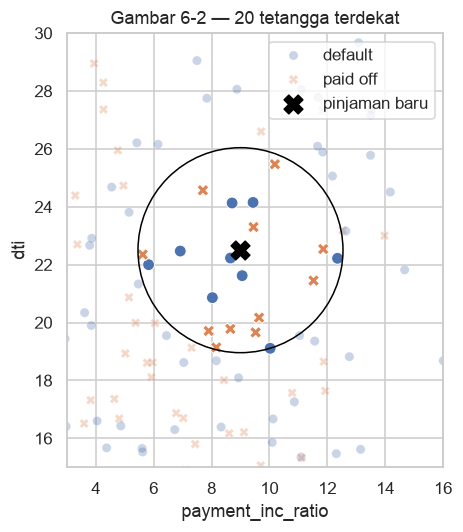

In [2]:
knn_predictors = ['payment_inc_ratio', 'dti']
newloan = loan200.loc[[0], knn_predictors]          # baris pertama berlabel 'target', bukan data latih
X200 = loan200.loc[1:, knn_predictors]
y200 = loan200.loc[1:, 'outcome']
knn = KNeighborsClassifier(n_neighbors=20).fit(X200, y200)
print('Pinjaman baru:', newloan.iloc[0].to_dict())
print('Prediksi:', knn.predict(newloan)[0])
display(pd.DataFrame(knn.predict_proba(newloan), columns=knn.classes_, index=['peluang']))

dist, idx = knn.kneighbors(newloan)
neighbors = X200.iloc[idx[0]].assign(outcome=y200.iloc[idx[0]].to_numpy())
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.scatterplot(data=loan200.loc[1:], x='payment_inc_ratio', y='dti', hue='outcome', style='outcome', alpha=.3, ax=ax)
sns.scatterplot(data=neighbors, x='payment_inc_ratio', y='dti', hue='outcome', style='outcome', s=60, ax=ax, legend=False)
ax.scatter(*newloan.to_numpy()[0], marker='X', s=150, color='black', label='pinjaman baru')
ax.add_patch(Circle(newloan.to_numpy()[0], dist[0].max(), fill=False, color='black'))
ax.set(xlim=(3, 16), ylim=(15, 30), aspect='equal', title='Gambar 6-2 — 20 tetangga terdekat')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Dari 20 tetangga, 11 paid off dan 9 default, jadi prediksinya **paid off** dengan peluang 0,55, sama seperti buku. Hasil ini hampir seimbang; menambah atau mengurangi K sedikit saja bisa mengubah prediksi. Lingkaran terlihat bulat karena kedua sumbu diberi skala sama (`aspect='equal'`); kalau skala berbeda, radius Euclidean akan tampak seperti elips.

<a id="c6-03"></a>
## Distance Metrics

*Jenis: Teori + contoh hitung tambahan.*

Jarak Euclidean $\sqrt{\sum_j (x_j-u_j)^2}$ paling umum. Jarak Manhattan $\sum_j |x_j-u_j|$ cocok kalau pergerakan hanya bisa sepanjang sumbu (seperti blok kota). Jarak Mahalanobis memperhitungkan korelasi antarvariabel memakai matriks kovarians, sehingga dua variabel yang sangat berkorelasi tidak "dihitung dua kali". Contoh di bawah menghitung ketiga jarak antara pinjaman baru dan record latih pertama.

In [3]:
a = X200.iloc[0].to_numpy(); b = newloan.iloc[0].to_numpy()
print('Euclidean:', round(np.sqrt(np.sum((a - b) ** 2)), 4))
print('Manhattan:', round(np.sum(np.abs(a - b)), 4))
# Mahalanobis memakai kovarians prediktor sehingga korelasi antar fitur diperhitungkan.
VI = np.linalg.inv(np.cov(X200.to_numpy().T))
print('Mahalanobis:', round(float(np.sqrt((a - b) @ VI @ (a - b))), 4))

Euclidean: 3.7195
Manhattan: 4.7007
Mahalanobis: 0.8476


**Interpretasi dan catatan belajar.** Untuk dua titik yang sama, angka jaraknya berbeda tergantung metrik. Mahalanobis jauh lebih kecil karena dibagi oleh sebaran data (mirip z-score multivariat). Yang penting bukan besar angkanya, tapi urutan tetangga yang dihasilkan, karena itulah yang dipakai KNN.

<a id="c6-04"></a>
## One Hot Encoder

*Jenis: Teori + contoh.*

KNN butuh jarak numerik, jadi variabel kategori harus diubah menjadi dummy. Berbeda dengan regresi, untuk KNN biasanya **semua** level dibuat kolom (one-hot), tanpa membuang satu level sebagai baseline, karena tidak ada masalah multikolinearitas di sini.

In [4]:
display(loan_data[['home_']].head(6).join(pd.get_dummies(loan_data['home_'].head(6), dtype=int)))

,home_,OWN,RENT
1,RENT,0,1
2,OWN,1,0
3,RENT,0,1
4,RENT,0,1
5,RENT,0,1
6,RENT,0,1


**Interpretasi dan catatan belajar.** `pd.get_dummies` membuat satu kolom 0/1 per level yang muncul. Karena di enam baris ini tidak ada MORTGAGE, kolomnya tidak muncul; pada data penuh akan ada tiga kolom.

<a id="c6-05"></a>
## Standardization (Normalization, z-Scores)

*Jenis: Reproduksi Python buku.*

Kalau satuan variabel berbeda jauh, variabel dengan angka besar akan mendominasi jarak. Standardisasi z-score $z=(x-\bar x)/s$ membuat semua variabel punya mean 0 dan standar deviasi 1. Contoh buku mencari 5 tetangga untuk satu pinjaman, sebelum dan sesudah standardisasi.

In [5]:
std_predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
newloan = loan_data.loc[[1], std_predictors]
X = loan_data.loc[loan_data.index[1:], std_predictors]
y = loan_data.loc[loan_data.index[1:], 'outcome']
print('Pinjaman yang dicari tetangganya:'); display(newloan)

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X, y)
_, idx_raw = knn_raw.kneighbors(newloan)
print('5 tetangga tanpa standardisasi:'); display(X.iloc[idx_raw[0]])

scaler = StandardScaler().fit(X * 1.0)
knn_std = KNeighborsClassifier(n_neighbors=5).fit(scaler.transform(X * 1.0), y)
_, idx_std = knn_std.kneighbors(scaler.transform(newloan * 1.0))
print('5 tetangga setelah z-score:'); display(X.iloc[idx_std[0]])
display(pd.DataFrame({'mean': scaler.mean_, 'std': scaler.scale_}, index=std_predictors))

Pinjaman yang dicari tetangganya:


,payment_inc_ratio,dti,revol_bal,revol_util
1,2.3932,1.0,1687,9.4


5 tetangga tanpa standardisasi:


,payment_inc_ratio,dti,revol_bal,revol_util
35537,1.47212,1.46,1686,10.0
33652,3.38178,6.37,1688,8.4
25864,2.36303,1.39,1691,3.5
42954,1.28160,7.14,1684,3.9
43600,4.12244,8.98,1684,7.2


5 tetangga setelah z-score:

,payment_inc_ratio,dti,revol_bal,revol_util
2081,2.61091,1.03,1218,9.7
1439,2.34343,0.51,278,9.9
30216,2.71200,1.34,1075,8.5
28543,2.39760,0.74,2917,7.4
44738,2.34309,1.37,488,7.2


,mean,std
payment_inc_ratio,8.032350,4.263952
dti,16.134065,7.594549
revol_bal,14857.737897,20082.444546
revol_util,56.052829,25.429332


**Interpretasi dan catatan belajar.** Tanpa standardisasi, kelima tetangga punya `revol_bal` hampir persis sama (1.684–1.691) tetapi `dti` dan `revol_util` cukup berbeda dari pinjaman yang dicari. Ini terjadi karena standar deviasi `revol_bal` ±20.000, jauh lebih besar dari variabel lain, sehingga jarak hampir sepenuhnya ditentukan `revol_bal`. Setelah z-score, tetangganya mirip di keempat variabel. Scaler di-fit pada data latih saja lalu dipakai juga untuk record baru.

<a id="c6-06"></a>
## Choosing K

*Jenis: Tambahan Python; konsep dari buku.*

K kecil membuat model mengikuti noise (overfitting); K besar membuat prediksi terlalu rata sehingga pola lokal hilang. Buku menyarankan memilih K dengan data validasi; biasanya K terbaik ada di kisaran 1–20 dan memakai angka ganjil untuk menghindari seri. Contoh ini membandingkan akurasi latih dan validasi untuk beberapa K pada empat prediktor yang sudah distandardisasi.

,akurasi latih,akurasi validasi
K,,
1,1.0000,0.5335
3,0.7680,0.5400
5,0.7130,0.5447
11,0.6603,0.5600
21,0.6343,0.5703
51,0.6126,0.5891
101,0.6073,0.5900
201,0.6027,0.5980


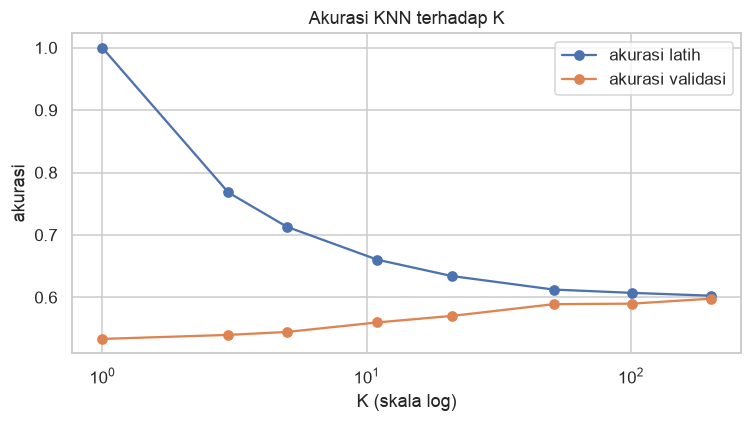

In [6]:
# Tambahan: pilih K dengan data validasi, bukan dari akurasi data latih.
Xk = loan_data[std_predictors]; yk = loan_data['outcome']
Xtr, Xva, ytr, yva = train_test_split(Xk, yk, test_size=0.3, random_state=SEED, stratify=yk)
sc = StandardScaler().fit(Xtr)
Xtr_s, Xva_s = sc.transform(Xtr), sc.transform(Xva)
k_values = [1, 3, 5, 11, 21, 51, 101, 201]
rows = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k).fit(Xtr_s, ytr)
    rows.append({'K': k, 'akurasi latih': accuracy_score(ytr, model.predict(Xtr_s)),
                 'akurasi validasi': accuracy_score(yva, model.predict(Xva_s))})
k_result = pd.DataFrame(rows).set_index('K')
display(k_result.round(4))
ax = k_result.plot(marker='o', logx=True, title='Akurasi KNN terhadap K')
ax.set(xlabel='K (skala log)', ylabel='akurasi'); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** K=1 memberi akurasi latih 100% (setiap titik adalah tetangga terdekat dirinya sendiri) tetapi akurasi validasi hanya ≈53%. Makin besar K, gap latih-validasi mengecil dan akurasi validasi naik sampai ≈60% di K=201. Di data ini K optimal jauh lebih besar dari 20 karena sinyalnya lemah dan data banyak; aturan praktis di buku tidak selalu berlaku.

<a id="c6-07"></a>
## KNN as a Feature Engine

*Jenis: Reproduksi Python buku.*

KNN juga bisa dipakai untuk membuat fitur baru. Peluang paid off dari KNN dimasukkan sebagai fitur ke model lain, mirip stacking. Fitur `borrower_score` yang dipakai di Bab 5 dibuat dengan cara ini dari enam variabel kredit.

,count,mean,std,min,25%,50%,75%,max
skor KNN (P paid off),45342.0,0.498901,0.128735,0.05,0.4,0.5,0.6,1.0


Korelasi dengan borrower_score bawaan data: 0.9996


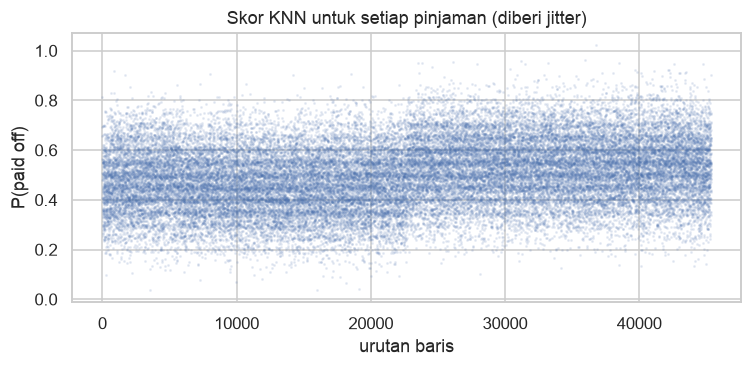

In [7]:
feat_predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc', 'delinq_2yrs_zero', 'pub_rec_zero']
X_feat = loan_data[feat_predictors]
y_feat = loan_data['outcome']
knn_feat = KNeighborsClassifier(n_neighbors=20).fit(X_feat, y_feat)
proba_paid = knn_feat.predict_proba(X_feat)[:, list(knn_feat.classes_).index('paid off')]
knn_score = pd.Series(proba_paid, index=loan_data.index, name='skor KNN (P paid off)')
display(knn_score.describe().to_frame().T)
print('Korelasi dengan borrower_score bawaan data:', round(knn_score.corr(loan_data.borrower_score), 4))

rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(range(len(knn_score)), knn_score + rng.normal(0, 0.015, len(knn_score)), s=1, alpha=.1)
ax.set(title='Skor KNN untuk setiap pinjaman (diberi jitter)', xlabel='urutan baris', ylabel='P(paid off)')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Skor KNN berkisar 0,05–1 dengan median 0,5, dan nilainya hanya kelipatan 0,05 karena K=20 (grafik jadi berpita; jitter ditambah supaya pita terlihat). Paruh pertama baris file berisi pinjaman default dan paruh kedua paid off, dan di grafik terlihat skor paruh kedua sedikit lebih tinggi. Korelasi dengan `borrower_score` di data ≈0,9996, jadi memang kolom itu dibuat dengan resep yang sama. Catatan penting: skor ini dihitung di data yang sama dengan data latih KNN, sehingga setiap record ikut menjadi tetangga dirinya sendiri. Kalau dipakai untuk model lain, skor sebaiknya dibuat dengan cross-validation agar tidak terjadi leakage.

<a id="c6-08"></a>
## Tree Models

*Jenis: Teori.*

Tree model (CART, decision tree) membagi data berulang-ulang dengan aturan seperti "jika borrower_score < 0,575 dan payment_inc_ratio ≥ 10,4 maka default". Kelebihannya mudah dijelaskan ke orang non-teknis dan bisa menangkap interaksi tanpa harus ditulis eksplisit. Tree tunggal biasanya kurang akurat, tetapi menjadi dasar random forest dan boosting.

<a id="c6-09"></a>
## A Simple Example

*Jenis: Reproduksi Python buku; visualisasi tanpa `dmba`.*

Tree dengan kriteria entropy dan `min_impurity_decrease=0.003` dipasang pada `loan3000`. Pada teks tree, `weights` adalah jumlah record [default, paid off] di daun itu.

|--- borrower_score <= 0.575
|   |--- borrower_score <= 0.325
|   |   |--- weights: [208.000, 57.000] class: default
|   |--- borrower_score >  0.325
|   |   |--- payment_inc_ratio <= 10.423
|   |   |   |--- weights: [631.000, 663.000] class: paid off
|   |   |--- payment_inc_ratio >  10.423
|   |   |   |--- weights: [345.000, 218.000] class: default
|--- borrower_score >  0.575
|   |--- payment_inc_ratio <= 9.191
|   |   |--- borrower_score <= 0.725
|   |   |   |--- weights: [128.000, 390.000] class: paid off
|   |   |--- borrower_score >  0.725
|   |   |   |--- weights: [6.000, 76.000] class: paid off
|   |--- payment_inc_ratio >  9.191
|   |   |--- weights: [127.000, 151.000] class: paid off



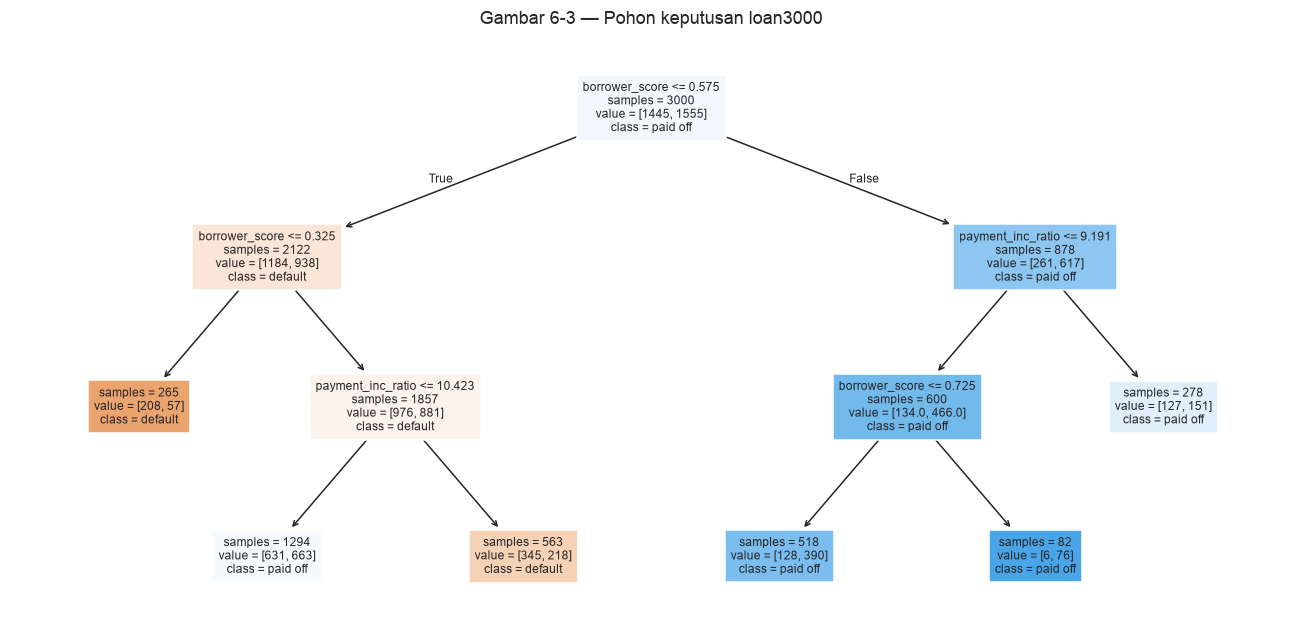

In [8]:
tree_predictors = ['borrower_score', 'payment_inc_ratio']
X3 = loan3000[tree_predictors]
y3 = loan3000['outcome']
loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy', min_impurity_decrease=0.003).fit(X3, y3)
print(export_text(loan_tree, feature_names=tree_predictors, decimals=3, show_weights=True))
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(loan_tree, feature_names=tree_predictors, class_names=list(loan_tree.classes_),
          filled=True, impurity=False, proportion=False, fontsize=8, ax=ax)
ax.set_title('Gambar 6-3 — Pohon keputusan loan3000'); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Split pertama di `borrower_score` 0,575, lalu 0,325, kemudian `payment_inc_ratio` 10,423 dan 9,191, persis seperti tree di buku. Daun paling kiri (skor ≤0,325) berisi 208 default dari 265 record (≈78%), jadi cukup "murni". Sebaliknya daun skor 0,325–0,575 dengan rasio ≤10,4 berisi 631 default vs 663 paid off, hampir 50:50. Prediksinya paid off, tapi keyakinannya rendah.

<a id="c6-10"></a>
## The Recursive Partitioning Algorithm

*Jenis: Reproduksi grafik buku; batas dihitung dari tree.*

Algoritmanya: untuk setiap prediktor dan setiap kemungkinan titik potong, hitung seberapa homogen dua bagian hasil potongan. Pilih potongan terbaik, lalu ulangi untuk tiap bagian sampai tidak ada potongan yang cukup memperbaiki homogenitas. Hasilnya adalah partisi persegi panjang. Kode buku mengetik koordinat garis secara manual; di sini partisi digambar langsung dari prediksi tree pada grid.

,node,fitur,threshold,n
0,0,borrower_score,0.575,3000
1,1,borrower_score,0.325,2122
3,3,payment_inc_ratio,10.423,1857
6,6,payment_inc_ratio,9.191,878
7,7,borrower_score,0.725,600


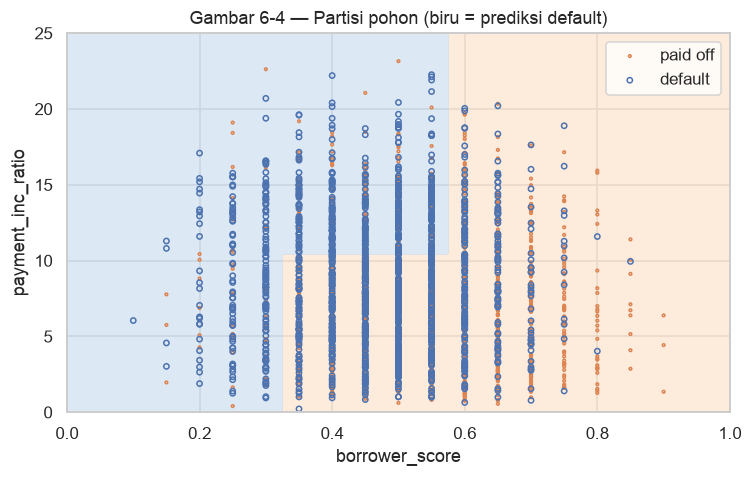

In [9]:
t = loan_tree.tree_
splits = pd.DataFrame({'node': range(t.node_count), 'fitur': [tree_predictors[f] if f >= 0 else '-' for f in t.feature],
                       'threshold': np.where(t.feature >= 0, t.threshold, np.nan), 'n': t.n_node_samples})
display(splits[splits.fitur != '-'].round(3))

# Batas partisi dibaca langsung dari pohon (bukan diketik manual) dengan menggambar prediksi di grid.
xx, yy = np.meshgrid(np.linspace(0, 1, 400), np.linspace(0, 25, 400))
Z = (loan_tree.predict(pd.DataFrame({'borrower_score': xx.ravel(), 'payment_inc_ratio': yy.ravel()})) == 'default').reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.contourf(xx, yy, Z, levels=[-.5, .5, 1.5], colors=['#fde0c5', '#c6dbef'], alpha=.6)
for cls, marker, color in [('paid off', '.', 'C1'), ('default', 'o', 'C0')]:
    sub = loan3000[loan3000.outcome == cls]
    ax.scatter(sub.borrower_score, sub.payment_inc_ratio, marker=marker, facecolors='none', edgecolors=color, s=12, label=cls)
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel='borrower_score', ylabel='payment_inc_ratio',
       title='Gambar 6-4 — Partisi pohon (biru = prediksi default)')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Area biru (prediksi default) ada di kiri (skor rendah) dan di tengah atas (skor menengah dengan rasio cicilan tinggi). Tabel split menunjukkan tree menggunakan `borrower_score` tiga kali dan `payment_inc_ratio` dua kali. Di setiap persegi panjang tetap banyak titik dari kelas lain, sesuai akurasi tree yang hanya ±61% di Bab 5.

<a id="c6-11"></a>
## Measuring Homogeneity or Impurity

*Jenis: Reproduksi grafik buku.*

Untuk partisi dengan proporsi kelas minoritas $p$:
- **Accuracy / misclassification**: $1-\max(p, 1-p)$; buruk dipakai untuk memilih split karena tidak peka terhadap perubahan kecil.
- **Gini impurity**: $I(A)=p(1-p)$ (di grafik diskalakan agar maksimumnya 1).
- **Entropy**: $I(A)=-p\log_2 p-(1-p)\log_2(1-p)$.

Ketiganya nol saat partisi murni dan maksimum saat $p=0{,}5$.

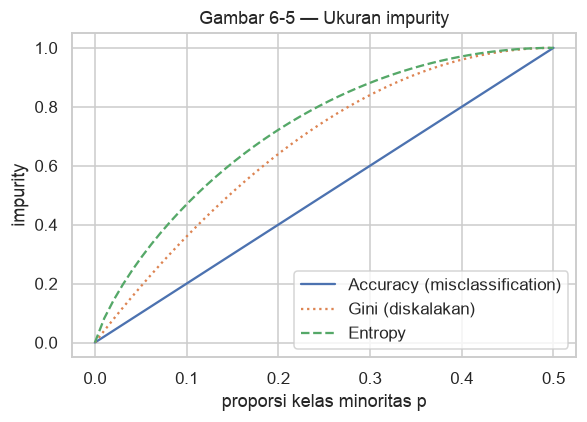

Node akar: p(default)=0.4817, entropy=0.9990, Gini=0.4993


In [10]:
def entropy(p):
    return 0.0 if p in (0, 1) else -p * math.log2(p) - (1 - p) * math.log2(1 - p)

def gini(p):
    return p * (1 - p)

p = np.linspace(0, 0.5, 50)
impure = pd.DataFrame({'p': p, 'Accuracy (misclassification)': 2 * p,
                       'Gini (diskalakan)': [gini(v) / gini(.5) for v in p],
                       'Entropy': [entropy(v) for v in p]})
ax = impure.plot(x='p', style=['-', ':', '--'], figsize=(5.5, 4))
ax.set(title='Gambar 6-5 — Ukuran impurity', xlabel='proporsi kelas minoritas p', ylabel='impurity')
plt.tight_layout(); plt.show()

root_p = (y3 == 'default').mean()
print(f'Node akar: p(default)={root_p:.4f}, entropy={entropy(root_p):.4f}, Gini={2 * gini(root_p):.4f}')

**Interpretasi dan catatan belajar.** Gini dan entropy melengkung, sehingga tetap memberi "hadiah" untuk split yang sedikit memperbaiki kemurnian; misclassification berupa garis lurus. Node akar `loan3000` hampir seimbang (p(default)=0,48) sehingga entropy-nya ≈0,999, hampir maksimum.

<a id="c6-12"></a>
## Stopping the Tree from Growing

*Jenis: Teori.*

Tree yang dibiarkan tumbuh sampai setiap daun murni akan menghafal noise. Cara menghentikannya: syarat ukuran minimum partisi/daun (`min_samples_split`, `min_samples_leaf`), syarat penurunan impurity minimum (`min_impurity_decrease`), atau batas kedalaman (`max_depth`). R memakai complexity parameter `cp` dan pruning dengan cross-validation. Contoh tree di atas memakai `min_impurity_decrease=0.003` sebagai pengganti `cp`.

<a id="c6-13"></a>
## Predicting a Continuous Value

*Jenis: Tambahan Python; konsep dari buku.*

Tree juga bisa untuk regresi: setiap daun memprediksi rata-rata target di partisinya, dan impurity diukur dengan squared error (RMSE). Contoh tambahan ini memprediksi `payment_inc_ratio` dari `borrower_score` dan `dti` dengan kedalaman 2.

In [11]:
# Tambahan: pohon regresi kecil untuk target kontinu (payment_inc_ratio dari borrower_score dan dti).
from sklearn.tree import DecisionTreeRegressor
reg_tree = DecisionTreeRegressor(max_depth=2, random_state=SEED).fit(loan_data[['borrower_score', 'dti']], loan_data['payment_inc_ratio'])
print(export_text(reg_tree, feature_names=['borrower_score', 'dti'], decimals=2))

|--- dti <= 15.89
|   |--- dti <= 7.48
|   |   |--- value: [6.39]
|   |--- dti >  7.48
|   |   |--- value: [7.58]
|--- dti >  15.89
|   |--- dti <= 25.09
|   |   |--- value: [8.49]
|   |--- dti >  25.09
|   |   |--- value: [9.81]



**Interpretasi dan catatan belajar.** Ketiga split memakai `dti`, dan rata-rata rasio cicilan naik dari ≈6,4 ke ≈9,8 seiring naiknya `dti`. Masuk akal karena keduanya sama-sama ukuran beban utang terhadap pendapatan. Prediksi tree regresi berbentuk anak tangga, bukan garis mulus.

<a id="c6-14"></a>
## How Trees Are Used

*Jenis: Teori.*

Dua alasan tree populer: hasilnya mudah divisualisasikan dan dijelaskan, serta aturan if-then-nya bisa langsung dipakai untuk eksplorasi atau bisnis. Kelemahannya, tree tunggal tidak stabil (data sedikit berubah, struktur tree bisa berubah total) dan akurasinya biasanya kalah dari model lain. Ensemble di bagian berikut mengatasi kelemahan ini.

<a id="c6-15"></a>
## Bagging and the Random Forest

*Jenis: Teori.*

Ide ensemble: rata-rata (atau voting) banyak model biasanya lebih akurat daripada satu model terbaik. Contoh terkenal adalah Netflix Prize, yang dimenangkan oleh gabungan banyak model. Bagging dan random forest menerapkan ide ini pada tree.

<a id="c6-16"></a>
## Bagging

*Jenis: Tambahan Python algoritme bagging buku.*

Bagging = **b**ootstrap **agg**regat**ing**. Ambil sampel bootstrap dari data latih, pasang satu tree, ulangi M kali, lalu gabungkan prediksinya dengan voting. Contoh berikut membandingkan satu tree penuh dengan bagging 100 tree pada data validasi.

In [12]:
# Bagging manual: banyak pohon pada sampel bootstrap lalu voting.
rng = np.random.default_rng(SEED)
Xtr, Xva, ytr, yva = train_test_split(X3, y3, test_size=0.3, random_state=SEED, stratify=y3)
single = DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr)
votes = []
for b in range(100):
    i = rng.integers(0, len(Xtr), len(Xtr))
    votes.append(DecisionTreeClassifier(random_state=b).fit(Xtr.iloc[i], ytr.iloc[i]).predict(Xva) == 'default')
bag_pred = np.where(np.mean(votes, axis=0) > 0.5, 'default', 'paid off')
print('Akurasi validasi satu pohon penuh:', round(accuracy_score(yva, single.predict(Xva)), 4))
print('Akurasi validasi bagging 100 pohon:', round(accuracy_score(yva, bag_pred), 4))

Akurasi validasi satu pohon penuh: 0.5411
Akurasi validasi bagging 100 pohon: 0.5622


**Interpretasi dan catatan belajar.** Satu tree tanpa batas kedalaman hanya ≈54% akurat di data validasi karena menghafal data latih. Bagging 100 tree menaikkan akurasi ke ≈56%. Perbaikannya berasal dari berkurangnya varians: kesalahan acak tiap tree saling meniadakan saat divoting.

<a id="c6-17"></a>
## Random Forest

*Jenis: Reproduksi Python buku.*

Random forest = bagging + pemilihan variabel acak: di setiap split, tree hanya boleh memilih dari subset acak prediktor (default $\sqrt{p}$). Ini membuat tree-tree di dalam forest lebih berbeda satu sama lain, sehingga rata-ratanya lebih stabil. Akurasi bisa diperkirakan tanpa data holdout dengan **out-of-bag (OOB)** error: setiap record dinilai hanya oleh tree yang tidak memakai record itu di sampel bootstrap-nya.

OOB accuracy (500 pohon): 0.5753


,default,paid off
32109,0.181319,0.818681
16982,0.267045,0.732955
25335,0.933333,0.066667
34580,0.173077,0.826923
14424,1.000000,0.000000


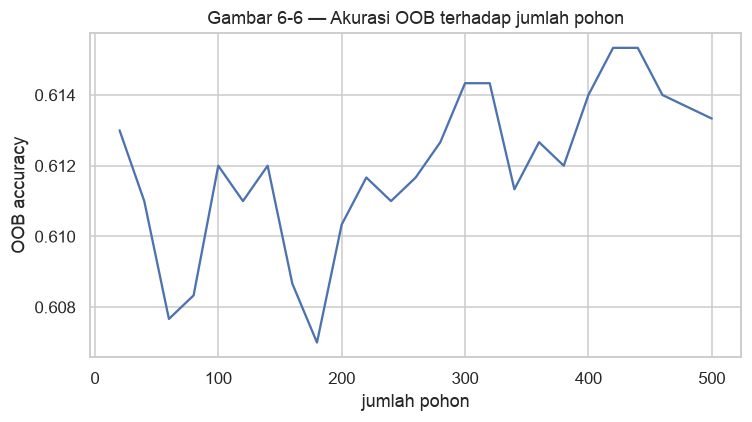

In [13]:
rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True, n_jobs=-1).fit(X3, y3)
print('OOB accuracy (500 pohon):', round(rf.oob_score_, 4))
display(pd.DataFrame(rf.oob_decision_function_, columns=rf.classes_, index=X3.index).head())

n_estimator = list(range(20, 510, 20))
oob_scores = [RandomForestClassifier(n_estimators=n, criterion='entropy', max_depth=5, random_state=1,
                                     oob_score=True, n_jobs=-1).fit(X3, y3).oob_score_ for n in n_estimator]
ax = pd.DataFrame({'jumlah pohon': n_estimator, 'OOB accuracy': oob_scores}).plot(x='jumlah pohon', y='OOB accuracy', legend=False)
ax.set(title='Gambar 6-6 — Akurasi OOB terhadap jumlah pohon', ylabel='OOB accuracy'); plt.tight_layout(); plt.show()

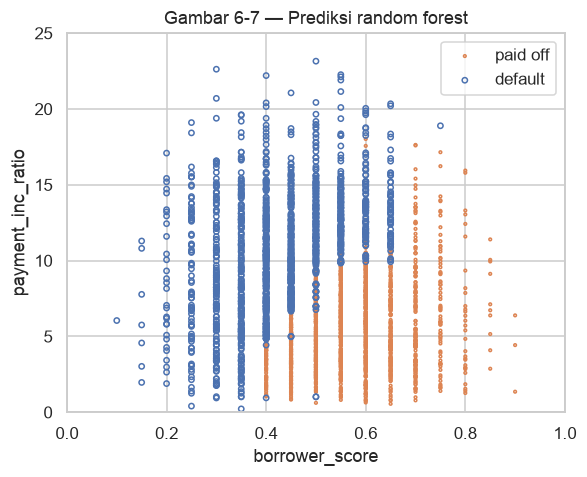

In [14]:
rf5 = RandomForestClassifier(n_estimators=500, criterion='entropy', max_depth=5, random_state=1, n_jobs=-1).fit(X3, y3)
pred_rf = pd.Series(rf5.predict(X3), index=X3.index)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cls, marker, color in [('paid off', '.', 'C1'), ('default', 'o', 'C0')]:
    sub = X3[pred_rf == cls]
    ax.scatter(sub.borrower_score, sub.payment_inc_ratio, marker=marker, facecolors='none', edgecolors=color, s=12, label=cls)
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel='borrower_score', ylabel='payment_inc_ratio', title='Gambar 6-7 — Prediksi random forest')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Forest dengan tree penuh punya OOB accuracy ≈57,5%. Membatasi kedalaman tree (`max_depth=5`) menaikkan OOB accuracy ke kisaran 0,607–0,615. Kurva itu naik-turun dalam rentang kurang dari satu poin persen dan tidak menunjukkan tren turun, jadi menambah tree tidak membuat forest overfit, hanya menambah waktu hitung. Kode buku memakai langkah 5 tree, di sini langkah 20 supaya lebih cepat. Grafik prediksi forest depth 5 cukup rapi: default di skor rendah, paid off di skor tinggi, dengan batas miring yang mirip regresi logistik di Bab 5, hanya sedikit bertangga.

<a id="c6-18"></a>
## Variable Importance

*Jenis: Reproduksi maksud analisis buku dengan `permutation_importance`.*

Random forest bisa memberi peringkat pentingnya variabel. Ada dua cara:
- **Penurunan akurasi**: acak (permutasi) nilai satu variabel di data validasi, lalu lihat berapa turunnya akurasi. Ini setara `type=1` di R.
- **Penurunan Gini (mean decrease impurity)**: total penurunan impurity dari semua split yang memakai variabel itu. Dihitung otomatis saat training (`feature_importances_`).

Model memakai 17 prediktor dari `loan_data`, dengan kategori diubah menjadi dummy. Kode buku mengulang permutasi di tiga split acak; di sini satu split 70/30 dipakai dengan `permutation_importance` (3 pengulangan).

Akurasi validasi RF (17 prediktor): 0.6703


/Users/happhify/Telkom/Machine Learning/Practical-Statistics-for-Data-Scientists/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Accuracy decrease,Gini decrease
borrower_score,0.0783,0.0871
grade,0.0476,0.0958
term_60 months,0.0374,0.0207
annual_inc,0.0206,0.0930
payment_inc_ratio,0.0162,0.1061
dti,0.0122,0.0992
revol_bal,0.0121,0.0933
loan_amnt,0.0097,0.0801


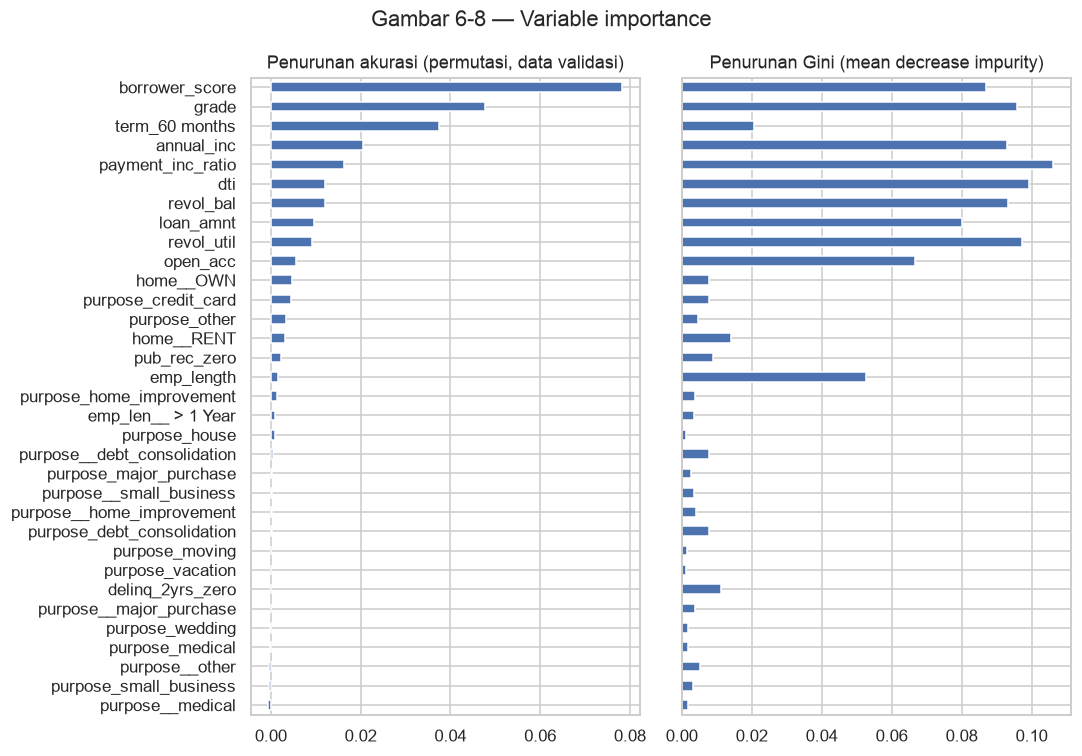

In [15]:
imp_predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio', 'revol_bal', 'revol_util',
                  'purpose', 'delinq_2yrs_zero', 'pub_rec_zero', 'open_acc', 'grade', 'emp_length',
                  'purpose_', 'home_', 'emp_len_', 'borrower_score']
X_all = pd.get_dummies(loan_data[imp_predictors], drop_first=True, dtype=int)
y_all = loan_data['outcome'].astype(str)
Xtr, Xva, ytr, yva = train_test_split(X_all, y_all, test_size=0.3, random_state=SEED)

rf_gini = RandomForestClassifier(n_estimators=200, random_state=1, n_jobs=-1).fit(Xtr, ytr)
acc_va = rf_gini.score(Xva, yva)
print('Akurasi validasi RF (17 prediktor):', round(acc_va, 4))
# Permutasi dihitung pada 5.000 baris validasi agar waktu eksekusi wajar.
Xperm, yperm = Xva.iloc[:5000], yva.iloc[:5000]
perm = permutation_importance(rf_gini, Xperm, yperm, n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({'Accuracy decrease': perm.importances_mean / rf_gini.score(Xperm, yperm),
                           'Gini decrease': rf_gini.feature_importances_}, index=X_all.columns)
importance = importance.sort_values('Accuracy decrease')
display(importance.sort_values('Accuracy decrease', ascending=False).head(8).round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 7), sharey=True)
importance['Accuracy decrease'].plot.barh(ax=axes[0], title='Penurunan akurasi (permutasi, data validasi)')
importance['Gini decrease'].plot.barh(ax=axes[1], title='Penurunan Gini (mean decrease impurity)')
fig.suptitle('Gambar 6-8 — Variable importance'); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Kedua ukuran sepakat `borrower_score` dan `grade` termasuk teratas, seperti di buku. Perbedaannya terlihat pada variabel numerik dengan banyak nilai unik (`payment_inc_ratio`, `dti`, `revol_bal`, `annual_inc`): Gini memberi skor tinggi, tetapi penurunan akurasinya kecil. Ini bias yang sudah dikenal dari Gini importance, karena variabel dengan banyak titik potong lebih sering terpilih. Contoh paling jelas adalah `emp_length`: Gini importance-nya ≈0,05, tetapi kalau nilainya diacak akurasi hampir tidak turun. Dummy `purpose` dan `home_` hampir nol di kedua ukuran.

<a id="c6-19"></a>
## Hyperparameters

*Jenis: Teori + contoh tambahan.*

Hyperparameter utama random forest: `min_samples_leaf` (ukuran daun minimum, `nodesize` di R) dan `max_leaf_nodes` (jumlah daun maksimum). Default scikit-learn membiarkan tree tumbuh penuh, yang bisa overfit pada data yang noisy. Contoh berikut melihat OOB accuracy untuk beberapa nilai `min_samples_leaf`.

In [16]:
# Tambahan: pengaruh nodesize/min_samples_leaf terhadap OOB accuracy.
leaf_result = pd.DataFrame([{'min_samples_leaf': leaf,
    'OOB accuracy': RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, random_state=1,
                                           oob_score=True, n_jobs=-1).fit(X3, y3).oob_score_}
    for leaf in [1, 5, 10, 25, 50, 100]]).set_index('min_samples_leaf')
display(leaf_result.round(4))

,OOB accuracy
min_samples_leaf,
1,0.5737
5,0.5913
10,0.5950
25,0.6013
50,0.6067
100,0.6117


**Interpretasi dan catatan belajar.** OOB accuracy naik dari ≈57,4% (daun minimal 1 record) ke ≈61,2% (daun minimal 100 record). Di data dengan sinyal lemah seperti ini, membatasi ukuran daun jelas membantu. Nilai optimalnya tetap perlu dicari per dataset.

<a id="c6-20"></a>
## Boosting

*Jenis: Teori.*

Boosting juga menggabungkan banyak model, tetapi secara berurutan: setiap model baru fokus memperbaiki kesalahan model-model sebelumnya. Varian yang paling banyak dipakai adalah AdaBoost, gradient boosting, dan stochastic gradient boosting. XGBoost adalah implementasi stochastic gradient boosting yang populer dan cepat.

<a id="c6-21"></a>
## The Boosting Algorithm

*Jenis: Tambahan Python algoritme AdaBoost buku.*

Langkah AdaBoost menurut buku: (1) mulai dengan bobot sama untuk semua record; (2) latih model dengan bobot itu; (3) hitung error tertimbang $e_m$ dan bobot model $\alpha_m=\tfrac12\log\frac{1-e_m}{e_m}$; (4) perbesar bobot record yang salah diklasifikasikan; (5) ulangi. Prediksi akhir adalah tanda dari $\sum_m\alpha_m f_m(x)$. Contoh di bawah memakai stump (tree satu split) sebagai model dasar.

In [17]:
# Ilustrasi algoritma boosting (AdaBoost) dengan stump: bobot kasus salah diperbesar tiap ronde.
y_pm = np.where(y3 == 'default', 1, -1)
w = np.full(len(y3), 1 / len(y3))
F = np.zeros(len(y3)); history = []
for m in range(1, 51):
    stump = DecisionTreeClassifier(max_depth=1, random_state=m).fit(X3, y_pm, sample_weight=w)
    pred = stump.predict(X3)
    err = np.sum(w * (pred != y_pm)) / w.sum()
    alpha = 0.5 * np.log((1 - err) / err)
    w = w * np.exp(-alpha * y_pm * pred); w = w / w.sum()
    F += alpha * pred
    history.append({'ronde': m, 'error tertimbang stump': err, 'akurasi ensemble (latih)': np.mean(np.sign(F) == y_pm)})
display(pd.DataFrame(history).iloc[[0, 1, 4, 9, 24, 49]].set_index('ronde').round(4))

,error tertimbang stump,akurasi ensemble (latih)
ronde,,
1,0.3997,0.6003
2,0.3979,0.5887
5,0.4873,0.6210
10,0.4833,0.6210
25,0.4963,0.6210
50,0.4954,0.6300


**Interpretasi dan catatan belajar.** Stump pertama punya error ≈0,40. Setelah bobot record yang salah diperbesar, stump berikutnya makin sulit; error tertimbangnya mendekati 0,5. Akurasi ensemble di data latih naik dari ≈60% ke ≈63% setelah 50 ronde. Gradient boosting bekerja dengan ide yang sama, hanya saja model baru di-fit ke residual (gradien loss), bukan dengan bobot.

<a id="c6-22"></a>
## XGBoost

*Jenis: Reproduksi Python buku.*

Dua parameter penting XGBoost: `subsample` (proporsi record yang diambil acak tiap iterasi) dan `learning_rate`/`eta` (faktor pengecil kontribusi tiap tree). Subsample membuat boosting mirip random forest; eta kecil mencegah overfitting.

,borrower_score,payment_inc_ratio,prediction,prob_default
32109,0.40,5.11135,paid off,0.251189
16982,0.40,5.43165,default,0.634665
25335,0.70,9.23003,default,0.587140
34580,0.40,2.33482,paid off,0.338984
14424,0.45,12.10320,default,0.912164


Akurasi latih XGBoost: 0.7573


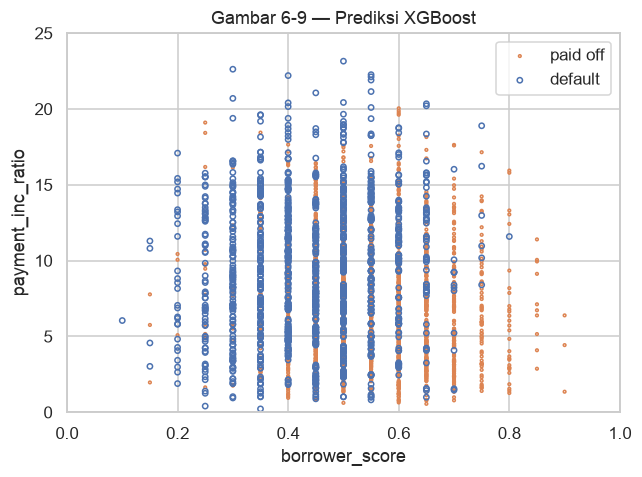

In [18]:
y3_01 = (y3 == 'default').astype(int)
xgb = XGBClassifier(objective='binary:logistic', subsample=.63, eval_metric='error', random_state=SEED)
xgb.fit(X3, y3_01)
xgb_df = X3.copy()
xgb_df['prediction'] = np.where(xgb.predict(X3) == 1, 'default', 'paid off')
xgb_df['prob_default'] = xgb.predict_proba(X3)[:, 1]
display(xgb_df.head())
print('Akurasi latih XGBoost:', round(accuracy_score(y3_01, xgb.predict(X3)), 4))

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, marker, color in [('paid off', '.', 'C1'), ('default', 'o', 'C0')]:
    sub = xgb_df[xgb_df.prediction == cls]
    ax.scatter(sub.borrower_score, sub.payment_inc_ratio, marker=marker, facecolors='none', edgecolors=color, s=12, label=cls)
ax.set(xlim=(0, 1), ylim=(0, 25), xlabel='borrower_score', ylabel='payment_inc_ratio', title='Gambar 6-9 — Prediksi XGBoost')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Akurasi latih XGBoost ≈0,757, jauh di atas tree/LDA/logistik (61–63%) pada data yang sama. Tapi grafik prediksinya terlihat acak: banyak titik diprediksi default di skor tinggi dan paid off di skor rendah, tidak membentuk batas yang rapi seperti model lain. Ini tanda overfitting; dengan parameter default (100 tree, kedalaman 6) model menghafal kombinasi nilai yang spesifik. Catatan kecil: kode buku mengisi `prob_default` dengan kolom indeks 0 dari `predict_proba`, yang sebenarnya P(paid off) karena target dikodekan default=1. Di sini dipakai kolom indeks 1.

<a id="c6-23"></a>
## Regularization: Avoiding Overfitting

*Jenis: Reproduksi Python buku.*

Kalau boosting dijalankan terlalu lama, model akan menghafal data latih. Contoh buku membandingkan XGBoost tanpa regularisasi (`reg_lambda=0`, eta 0,3, tanpa subsample) dengan versi yang diberi penalti (`reg_lambda=1000`, eta 0,1, subsample 0,63). 10.000 record dipisahkan sebagai data uji.

In [19]:
X_xgb = X_all
y_xgb = (loan_data['outcome'] == 'default').astype(int)
train_X, valid_X, train_y, valid_y = train_test_split(X_xgb, y_xgb, test_size=10000, random_state=SEED)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6, reg_lambda=0,
                            learning_rate=0.3, subsample=1, eval_metric='error', random_state=SEED)
xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=6, reg_lambda=1000,
                            learning_rate=0.1, subsample=0.63, eval_metric='error', random_state=SEED)
xgb_default.fit(train_X, train_y); xgb_penalty.fit(train_X, train_y)

def error_rate(model, X, y, n=None):
    kwargs = {} if n is None else {'iteration_range': (0, n)}
    return np.mean(np.abs(y - model.predict_proba(X, **kwargs)[:, 1]) > 0.5)

display(pd.DataFrame({'train': [error_rate(xgb_default, train_X, train_y), error_rate(xgb_penalty, train_X, train_y)],
                      'validasi': [error_rate(xgb_default, valid_X, valid_y), error_rate(xgb_penalty, valid_X, valid_y)]},
                     index=['default (lambda=0, eta=0.3)', 'penalty (lambda=1000, eta=0.1)']).round(4))

,train,validasi
"default (lambda=0, eta=0.3)",0.1090,0.3590
"penalty (lambda=1000, eta=0.1)",0.3115,0.3294


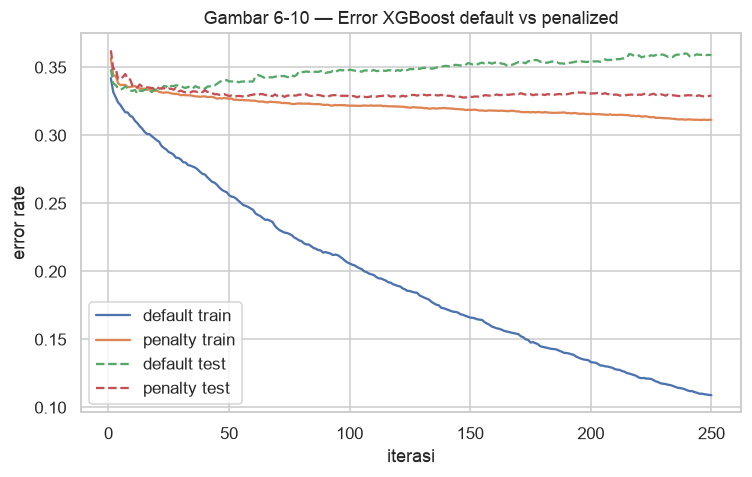

,default train,penalty train,default test,penalty test
iterasi,,,,
1,0.3421,0.3566,0.3486,0.3625
10,0.3135,0.3360,0.3327,0.3364
50,0.2561,0.3269,0.3396,0.3289
100,0.2058,0.3218,0.3483,0.3284
250,0.1090,0.3115,0.3590,0.3294


In [20]:
results = pd.DataFrame([{'iterasi': n,
    'default train': error_rate(xgb_default, train_X, train_y, n),
    'penalty train': error_rate(xgb_penalty, train_X, train_y, n),
    'default test': error_rate(xgb_default, valid_X, valid_y, n),
    'penalty test': error_rate(xgb_penalty, valid_X, valid_y, n)} for n in range(1, 251)])
ax = results.plot(x='iterasi', style=['-', '-', '--', '--'], figsize=(7, 4.5))
ax.set(title='Gambar 6-10 — Error XGBoost default vs penalized', ylabel='error rate')
plt.tight_layout(); plt.show()
display(results.iloc[[0, 9, 49, 99, 249]].set_index('iterasi').round(4))

**Interpretasi dan catatan belajar.** Model tanpa penalti mencapai error latih 10,9% tetapi error uji 35,9%. Model dengan penalti punya error latih 31,2% dan error uji 32,9%, jadi lebih jelek di data latih tetapi lebih baik di data baru. Grafik memperlihatkan error uji model default paling rendah di sekitar iterasi 10 (≈33%) lalu terus naik, sementara error latihnya terus turun. Model berpenalti hampir datar di ≈33% untuk data latih maupun uji. Pola ini sama dengan contoh di buku.

<a id="c6-24"></a>
## Ridge Regression and the Lasso

*Jenis: Teori.*

Regularisasi XGBoost mirip dengan regresi ridge dan lasso. Ridge meminimalkan $\sum_i(Y_i-\hat Y_i)^2+\lambda\sum_j b_j^2$, sehingga koefisien besar dihukum. Lasso memakai $\lambda\sum_j|b_j|$ yang bisa membuat koefisien tepat nol. Di XGBoost, `reg_lambda` adalah penalti kuadrat (seperti ridge) dan `reg_alpha` penalti absolut (seperti lasso), dikenakan pada bobot daun.

<a id="c6-25"></a>
## Hyperparameters and Cross-Validation

*Jenis: Reproduksi Python buku; fold dibuat dengan `KFold`.*

XGBoost punya banyak hyperparameter, dan memilihnya dengan melihat error data latih pasti berujung overfitting. Contoh buku mencoba 9 kombinasi `eta` ∈ {0,1; 0,5; 0,9} dan `max_depth` ∈ {3, 6, 9} dengan 5-fold cross-validation. Kode buku membuat fold dengan `np.random.choice` sehingga ukuran fold tidak sama; di sini dipakai `KFold(shuffle=True)`.

In [21]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(kf.split(X_xgb))
error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    cv_error = []
    for tr, va in folds:
        model = XGBClassifier(objective='binary:logistic', n_estimators=250, max_depth=max_depth,
                              learning_rate=eta, eval_metric='error', random_state=SEED, n_jobs=-1)
        model.fit(X_xgb.iloc[tr], y_xgb.iloc[tr])
        cv_error.append(np.mean(np.abs(y_xgb.iloc[va] - model.predict_proba(X_xgb.iloc[va])[:, 1]) > 0.5))
    error.append({'eta': eta, 'max_depth': max_depth, 'avg_error': np.mean(cv_error)})
errors = pd.DataFrame(error)
display((errors.pivot_table(index='eta', columns='max_depth', values='avg_error') * 100).round(2))
best = errors.loc[errors.avg_error.idxmin()]
print(f"Kombinasi terbaik: eta={best.eta}, max_depth={int(best.max_depth)}, error CV={100 * best.avg_error:.2f}%")

max_depth,3,6,9
eta,,,
0.1,32.80,33.77,34.89
0.5,34.06,37.21,36.99
0.9,35.33,38.86,38.58


Kombinasi terbaik: eta=0.1, max_depth=3, error CV=32.80%


**Interpretasi dan catatan belajar.** Error CV terendah 32,80% pada eta=0,1 dan max_depth=3; tertinggi 38,86% pada eta=0,9 dan max_depth=6. Error cenderung naik saat eta atau kedalaman bertambah, artinya model yang lebih agresif makin overfit di data ini. Selisih antara kombinasi terbaik dan terburuk ±6 poin persen, cukup besar untuk menunjukkan bahwa default hyperparameter tidak boleh dipakai begitu saja.

<a id="c6-26"></a>
## Summary

*Jenis: Teori.*

KNN, tree, random forest, dan boosting bisa menangkap pola nonlinear tanpa harus menuliskan bentuk modelnya. Hasil bab ini menunjukkan dua hal yang berulang: standardisasi sangat menentukan tetangga di KNN, dan semua model fleksibel (K kecil, tree penuh, boosting tanpa penalti) tampak bagus di data latih tetapi turun di data validasi. Random forest dan XGBoost dengan hyperparameter yang dipilih lewat validasi memberi hasil paling stabil: akurasi validasi random forest 17 prediktor ≈67%, dan error CV XGBoost terbaik ≈32,8%.

**Latihan:** jelaskan mengapa K=1 selalu memberi akurasi latih 100%; hitung entropy node dengan 30 default dan 70 paid off; jelaskan perbedaan bagging dan random forest; jelaskan mengapa OOB error tidak membutuhkan data holdout; dari tabel CV, pilih hyperparameter XGBoost dan jelaskan alasannya.

**Batas hasil:** semua contoh memakai data dan parameter buku. Variable importance menunjukkan asosiasi dalam model, bukan sebab-akibat, dan model ini bukan sistem penilaian kredit siap pakai.

## Referensi dan atribusi

- Peter Bruce, Andrew Bruce, Peter Gedeck. *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi 2, O’Reilly, 2020. ISBN 978-1-492-07294-2, Bab 6.
- [Kode dan dataset resmi pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); sumber khusus: `python/code/Chapter 6 - Statistical Machine Learning.py`. Copyright kode upstream © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck. Modifikasi untuk tugas: penjelasan Indonesia, seed eksplisit, visualisasi tree tanpa `dmba`, `permutation_importance`, `KFold`, serta contoh tambahan (pilihan K, pohon regresi, bagging, AdaBoost) yang ditandai. Lisensi GPL-3.0: lihat [LICENSE](LICENSE).
- Dokumentasi [scikit-learn](https://scikit-learn.org/) dan [XGBoost](https://xgboost.readthedocs.io/).

**Refleksi mahasiswa:**